# PharmaFlow Foundation: five charts for Medical Affairs

The analysis deliverable of the PharmaFlow Foundation project (Session 2.3 Lab),
built on 6,218 real openFDA adverse-event reports, 2024-07 to 2026-06
(`data/raw/adverse_events_10k.csv`).

Two choices, because the data has no severity score and no single number per
drug class: the **severity heatmap** shows the **serious share** by reaction
category and quarter, and the **drug class box plot** shows **patient age in
years** for the five largest named drug classes. Reaction categories come from
`data/raw/reaction_categories.csv`, built for this course (not MedDRA).

In [1]:
import os
import textwrap
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def find_repo_root(marker_folder="data", start=None):
    """Search upward from the current folder for the folder that contains
    `data` -- that folder is the repo root."""
    current = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(current, marker_folder)):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise FileNotFoundError(f"No '{marker_folder}' folder above here")
        current = parent


ROOT = find_repo_root()
RAW = os.path.join(ROOT, "data", "raw")
OUT = os.path.join(ROOT, "data", "processed", "charts")
os.makedirs(OUT, exist_ok=True)
BLUE, TERRA, GRAY = "#2E74B5", "#C0392B", "#9AA5B1"

TYPES = {"safety_report_id": str, "serious": str, "patient_age_unit": str,
         "country": str, "event_date": str}
df = pd.read_csv(os.path.join(RAW, "adverse_events_10k.csv"), dtype=TYPES)
ref = pd.read_csv(os.path.join(RAW, "drug_reference.csv"))
rmap = pd.read_csv(os.path.join(RAW, "reaction_categories.csv"))
df["is_serious"] = df["serious"].map({"1": 1.0, "2": 0.0})
df["day"] = pd.to_datetime(df["event_date"], format="%Y%m%d")
df["quarter"] = df["day"].dt.to_period("Q").astype(str)
YEARS = {"800": 10, "801": 1, "802": 1 / 12, "803": 7 / 365.25,
         "804": 1 / 365.25, "805": 1 / (24 * 365.25)}
df["age_years"] = (pd.to_numeric(df["patient_age"], errors="coerce")
                   * df["patient_age_unit"].map(YEARS))
df = df.merge(rmap, on="reaction", how="left", validate="many_to_one")
df["reaction_category"] = df["reaction_category"].fillna("Unmapped")
df = df.merge(ref[["drug_name", "drug_class"]], on="drug_name", how="left",
              validate="many_to_one")
print(len(df), "reports")

6218 reports


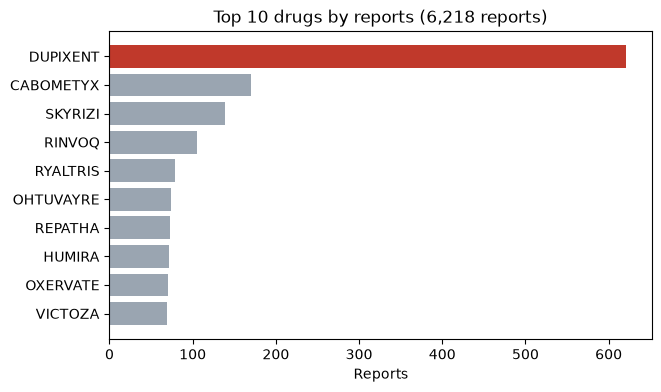

In [2]:
top10 = df["drug_name"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top10.index[::-1], top10.values[::-1], color=[GRAY] * 9 + [TERRA])
ax.set_title("Top 10 drugs by reports (6,218 reports)")
ax.set_xlabel("Reports")
fig.savefig(os.path.join(OUT, "lab1_top10_drugs.png"), dpi=200,
            bbox_inches="tight")
plt.show()

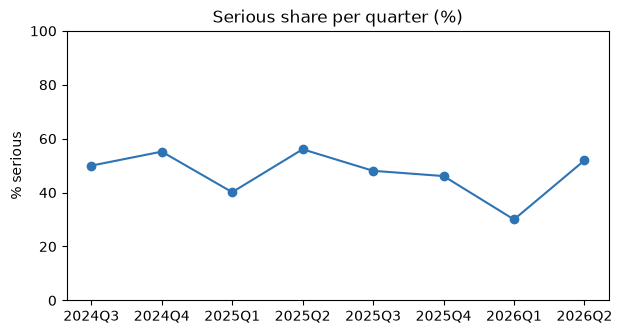

In [3]:
q = df.groupby("quarter")["is_serious"].mean().mul(100)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(q.index, q.values, marker="o", color=BLUE)
ax.set_ylim(0, 100)
ax.set_title("Serious share per quarter (%)")
ax.set_ylabel("% serious")
fig.savefig(os.path.join(OUT, "lab2_serious_share_quarter.png"), dpi=200,
            bbox_inches="tight")
plt.show()

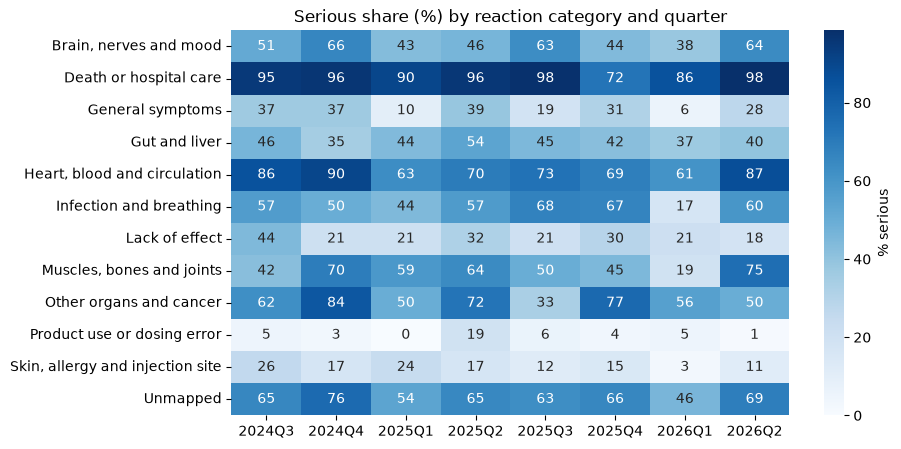

In [4]:
hm = df.pivot_table(index="reaction_category", columns="quarter",
                    values="is_serious", aggfunc="mean").mul(100)
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(hm, annot=True, fmt=".0f", cmap="Blues", ax=ax,
            cbar_kws={"label": "% serious"})
ax.set_title("Serious share (%) by reaction category and quarter")
ax.set_xlabel("")
ax.set_ylabel("")
fig.savefig(os.path.join(OUT, "lab3_heatmap.png"), dpi=200,
            bbox_inches="tight")
plt.show()

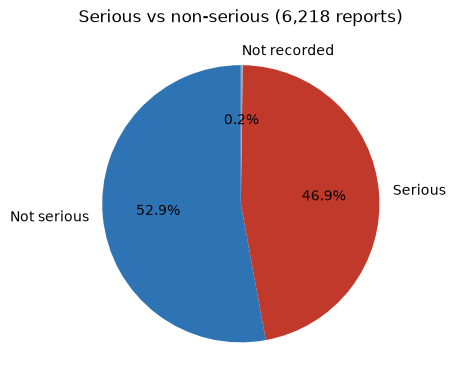

In [5]:
labels = {"1": "Serious", "2": "Not serious"}
pie = df["serious"].map(labels).fillna("Not recorded").value_counts()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.pie(pie.values, labels=pie.index, autopct="%1.1f%%",
       colors=[BLUE, TERRA, GRAY], startangle=90)
ax.set_title("Serious vs non-serious (6,218 reports)")
fig.savefig(os.path.join(OUT, "lab4_pie.png"), dpi=200, bbox_inches="tight")
plt.show()

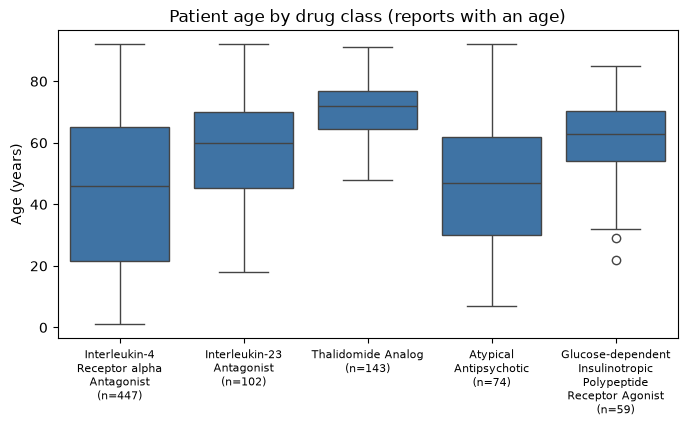

In [6]:
top5 = df["drug_class"].value_counts().head(5).index
ages = df[df["drug_class"].isin(top5)].dropna(subset=["age_years"])
n = ages["drug_class"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
with warnings.catch_warnings():  # seaborn 0.13.2 'vert' warning, harmless
    warnings.simplefilter("ignore")
    sns.boxplot(data=ages, x="drug_class", y="age_years", order=list(top5),
                color=BLUE, ax=ax)
ax.set_xticks(range(5), [textwrap.fill(c, 18) + f"\n(n={n[c]})"
                         for c in top5], fontsize=8)
ax.set_xlabel("")
ax.set_ylabel("Age (years)")
ax.set_title("Patient age by drug class (reports with an age)")
fig.savefig(os.path.join(OUT, "lab5_age_by_class.png"), dpi=200,
            bbox_inches="tight")
plt.show()

## The five charts on one page

The README shows this picture; the cell rebuilds it from the five PNG files.

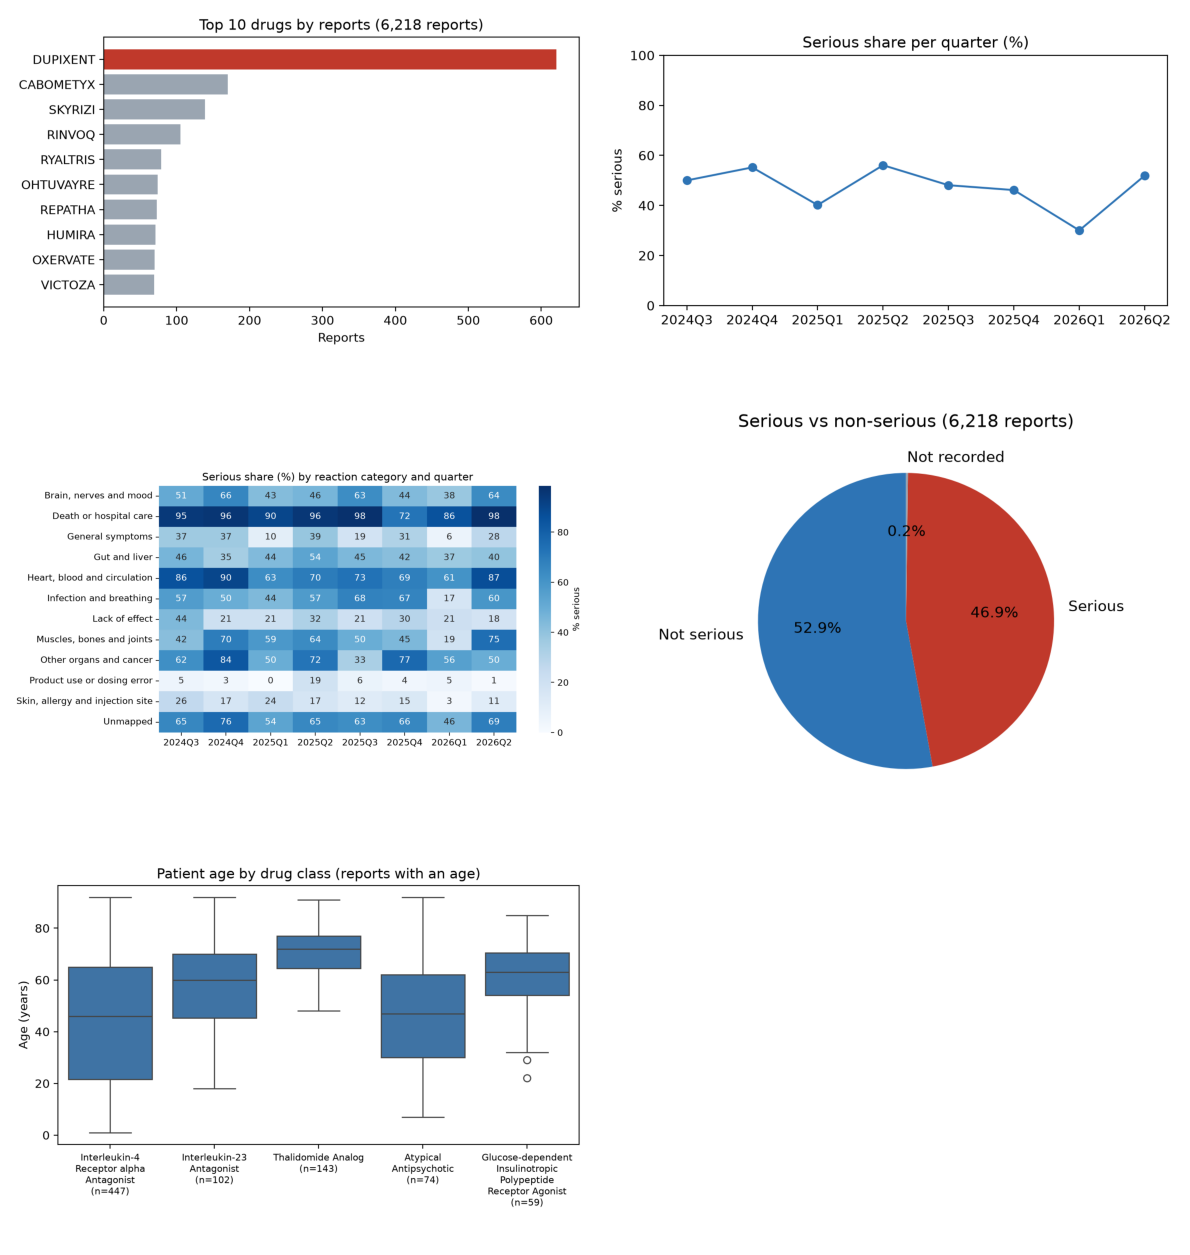

In [7]:
import matplotlib.image as mpimg

names = ["lab1_top10_drugs", "lab2_serious_share_quarter", "lab3_heatmap",
         "lab4_pie", "lab5_age_by_class"]
fig, axes = plt.subplots(3, 2, figsize=(12, 13))
for ax, name in zip(axes.flat, names):
    ax.imshow(mpimg.imread(os.path.join(OUT, name + ".png")))
    ax.axis("off")
axes.flat[-1].axis("off")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "foundation_5_charts.png"), dpi=100)
plt.show()

## Notes for Medical Affairs

1. **Top 10 drugs:** DUPIXENT leads with 621 of 6,218 reports, more than the next three together.
2. **Serious share per quarter:** between 30% and 56%; the 2026 Q1 low comes from four single-drug bulk submissions, not a safety change.
3. **Heatmap:** death or hospital-care reactions are serious in almost every report; each cell is a share, so read it with the number of reports behind it (the smallest cell has 20).
4. **Pie:** 46.9% serious, 52.9% not serious, 13 reports not recorded.
5. **Box plot:** patient age in years, only for reports with an age (`n` under each box).

The sample took about the same number of reports from every quarter, so counts describe the sample, not reporting volume.